# Phase 3C | High-Activity-Aware Neural Digital Twin + Robust Uncertainty

**Real dataset:** DANDI 000568 (version `0.230705.1633`). Two sessions from **one mouse** (`fCamk1`). There is **no independent-animal test** and **no validated optogenetic intervention effect**.

**Primary research question:** Can stronger weighting of rare high firing-rate outcomes reduce their prediction errors, without destroying ordinary prediction accuracy? Can model-uncertainty intervals be improved using an **observable neural-history state**, rather than future (unavailable) activity labels?

**REAL experiments:** GRU (standard), GRU (peak-weighted), Hybrid GRU (peak-weighted); 0.1 / 1 / 3 / 6 second prediction, 2 held-out-session directions, three model seeds each (quick mode), calibration on a *separate chronological period of the training session*, interval diagnostics, and six-second recursive predictions. **No measured light response is used for model fitting.**

**SIMULATED ONLY:** Optional receding-horizon controller prototype driven by a **hypothesized and uncalibrated** inhibitory-light gain. Its numerical outcomes are not evidence of optical efficacy, epilepsy suppression, intervention safety, or patient personalization.

**Dataset / statistical limitations:** Only one mouse; temporally correlated bins; cross-session distribution shift. Nominal 90% conformal intervals **do not come with cross-session coverage guarantees**. Report empirically observed test coverage and peak-target coverage separately. Peak-target status is known only for *retrospective scoring*, not controller inputs.

**Kaggle:** Internet ON, CPU/Accelerator=None, no attached input. Keep `QUICK_MODE=True` initially. Output: `phase3c_peak_aware_twin_results.zip`.

## 1. Environment and experiment settings

`QUICK_MODE=True` trains 3 ensemble members per architecture and uses capped sample sizes. `USE_GPU=False` avoids GPU queueing. The notebook requires no prior ZIP input; it retrieves just two small NWB assets (~73 MB total).

In [1]:
import sys, importlib.util, subprocess
for package, module in [('requests','requests'),('h5py','h5py'),('numpy','numpy'),('pandas','pandas'),
                        ('scipy','scipy'),('matplotlib','matplotlib'),('scikit-learn','sklearn'),('torch','torch')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])

import copy, json, zipfile, re, random, math, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, h5py
from scipy.ndimage import binary_dilation
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED=20261013
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
QUICK_MODE=True
USE_GPU=False  # Avoid queuing for a GPU; toggle only when needed
DEVICE=torch.device('cuda' if USE_GPU and torch.cuda.is_available() else 'cpu')
DANDISET='000568';VERSION='0.230705.1633';BASE='https://api.dandiarchive.org'
BIN_SEC=0.1; HISTORY_BINS=20
HORIZONS=np.array([1,10,30,60],dtype=int)  # 100 ms, 1 s, 3 s, 6 s
HORIZON_NAMES=['0.1s','1s','3s','6s']
MAX_H=int(HORIZONS.max())
LIGHT_GUARD_SEC=0.3
STRIDE_BINS=10  # 1-second anchor spacing; still correlated outcomes
N_ENSEMBLE=3 if QUICK_MODE else 5
EPOCHS=10 if QUICK_MODE else 25
BATCH_SIZE=128
CAPS=({'train':2400,'val':400,'calib':400,'test':900} if QUICK_MODE else
      {'train':11000,'val':1700,'calib':1700,'test':3300})
N_ROLLOUT_SEGMENTS=8 if QUICK_MODE else 20
PEAK_WEIGHT=4.0
HISTORY_STATE_TRAIN_QUANTILE=.80
MIN_GROUP_CALIB=40
N_MPC_STEPS=70 if QUICK_MODE else 140
BLOCK_BOOTSTRAP_REPS=250 if QUICK_MODE else 1000
ALPHA=0.10
ROOT=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT=ROOT/'phase3c_outputs';CACHE=ROOT/'phase3c_nwb_cache'
OUT.mkdir(parents=True,exist_ok=True);CACHE.mkdir(parents=True,exist_ok=True)
FOLDS=[('session_9','session_12'),('session_12','session_9')]
print('Device:',DEVICE,'Quick:',QUICK_MODE,'Ensemble per family:',N_ENSEMBLE)
print('Forecast horizons (sec):',HORIZONS*BIN_SEC)
print('OUTPUT:',OUT)

Device: cpu Quick: True Ensemble per family: 3
Forecast horizons (sec): [0.1 1.  3.  6. ]
OUTPUT: /kaggle/working/phase3c_outputs


## 2. Download version-pinned DANDI recordings

Use optogenetics-labeled small NWB files, but the target here is **spontaneous neural dynamics** from guarded **light-free** windows. Do not interpret optical codes as real watts.

In [2]:
def api_json(url):
    r=requests.get(url,timeout=(20,80),headers={'Accept':'application/json'})
    r.raise_for_status();return r.json()
assets=[];url=f'{BASE}/api/dandisets/{DANDISET}/versions/{VERSION}/assets/'
while url:
    d=api_json(url)
    assets.extend(d['results']);url=d.get('next')
manifest=pd.DataFrame([{'asset_id':a['asset_id'],'path':a['path'],'size_bytes':int(a['size'])} for a in assets])
selected=manifest[manifest.path.str.endswith('.nwb') &
                  manifest.path.str.contains('+ogen',regex=False) &
                  manifest.path.str.contains('no-raw-data',regex=False) &
                  (manifest.size_bytes<70_000_000)].sort_values('size_bytes').copy()
if len(selected)!=2:raise RuntimeError(f'Expected 2 small optogenetic files, found {len(selected)}')
selected.to_csv(OUT/'REAL_manifest_pinned.csv',index=False)

def download_asset(row):
    expected=int(row['size_bytes'])
    if expected>70_000_000:raise RuntimeError('Oversize asset blocked')
    path=CACHE/Path(row['path']).name
    if path.exists() and path.stat().st_size==expected:return path
    part=path.with_name(path.name+'.part')
    with requests.get(f"{BASE}/api/assets/{row['asset_id']}/download/",stream=True,timeout=(30,180)) as response:
        response.raise_for_status()
        with part.open('wb') as stream:
            for block in response.iter_content(chunk_size=1_048_576):
                if block:stream.write(block)
    if part.stat().st_size!=expected:raise IOError('Downloaded asset size mismatch')
    part.replace(path);print('Downloaded',path.name,round(expected/1e6,2),'MB')
    return path
session_files={}
for _,row in selected.iterrows():
    m=re.search(r'sess(\d+)',row['path'])
    if not m:raise RuntimeError('Missing session name: '+row['path'])
    session_files['session_'+m.group(1)]=download_asset(row)
assert set(session_files)=={'session_9','session_12'}
print('Using sessions:',sorted(session_files))

Downloaded sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb 28.68 MB
Downloaded sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb 44.44 MB
Using sessions: ['session_12', 'session_9']


## 3. Load sorted neural activity and mark guarded light intervals

The outcome is population spike rate (Hz per sorted unit) in 100-ms bins. Exclude measured light intervals plus a guard on both sides for all real-model examples.

In [3]:
def read_light_events(hf,label):
    root=hf.get('/stimulus/presentation')
    if root is None:raise RuntimeError('Missing stimulus/presentation group')
    rows=[]
    for name,g in root.items():
        if not isinstance(g,h5py.Group) or not name.startswith('OptogeneticSeriesSite'):
            continue
        if 'data' not in g or 'timestamps' not in g:continue
        t=np.asarray(g['timestamps'][:],dtype=float)
        v=np.asarray(g['data'][:],dtype=float).reshape(-1)
        if len(t)!=len(v) or len(t)<3 or np.any(np.diff(t)<0):continue
        on=np.isfinite(v)&(v>0)
        starts=np.flatnonzero(on&~np.r_[False,on[:-1]])
        stops=np.flatnonzero(~on&np.r_[False,on[:-1]])
        if on[0]:starts=starts[1:]
        ix=np.searchsorted(stops,starts,side='right')
        for st,i in zip(starts,ix):
            if i>=len(stops):continue
            en=stops[i]
            if np.isfinite(t[st]) and np.isfinite(t[en]) and 0<=t[st]<t[en]:
                rows.append({'session':label,'site':name,'on_sec':float(t[st]),
                             'off_sec':float(t[en]),'duration_sec':float(t[en]-t[st])})
    if not rows:raise RuntimeError('No complete optical-command intervals found in '+label)
    return pd.DataFrame(rows)

def light_overlap_mask(events,n):
    delta=np.zeros(n+1,dtype=np.int32)
    st=np.floor(events.on_sec.to_numpy()/BIN_SEC).astype(int)
    ed=np.floor(np.nextafter(events.off_sec.to_numpy(),-np.inf)/BIN_SEC).astype(int)
    ok=(st>=0)&(st<n)&(ed>=st)
    st=st[ok];ed=np.minimum(ed[ok],n-1)
    np.add.at(delta,st,1);np.add.at(delta,ed+1,-1)
    return np.cumsum(delta[:-1])>0

def load_real_session(label,path):
    with h5py.File(path,'r') as hf:
        if '/units/spike_times' not in hf or '/units/spike_times_index' not in hf:
            raise RuntimeError('No sorted spikes in '+label)
        spikes=np.asarray(hf['/units/spike_times'][:],dtype=np.float64)
        n_units=len(hf['/units/spike_times_index'])
        events=read_light_events(hf,label)
    spikes=spikes[np.isfinite(spikes)&(spikes>=0)]
    if not len(spikes) or not n_units:raise RuntimeError('Empty neural recording')
    if events.on_sec.min()<spikes.min() or events.on_sec.max()>spikes.max():
        raise RuntimeError('Optical event/spike time ranges do not overlap safely')
    n=int(np.ceil(max(spikes.max(),events.off_sec.max())/BIN_SEC))+1
    counts=np.bincount(np.floor(spikes/BIN_SEC).astype(np.int64),minlength=n)
    rate=np.asarray(counts/(n_units*BIN_SEC),dtype=np.float32)
    light=light_overlap_mask(events,n)
    guard=max(1,int(math.ceil(LIGHT_GUARD_SEC/BIN_SEC)))
    near_light=binary_dilation(light,structure=np.ones(2*guard+1,dtype=bool))
    return {'session':label,'rate':rate,'near_light':near_light,'light':light,
            'events':events,'n_units':n_units,'n_spikes':len(spikes),'n_bins':n}

sessions={k:load_real_session(k,v) for k,v in sorted(session_files.items())}
inv=pd.DataFrame([{'session':s['session'],'n_units':s['n_units'],'n_spikes':s['n_spikes'],
                   'n_optical_commands':len(s['events']),'recording_seconds':s['n_bins']*BIN_SEC,
                   'guarded_light_free_fraction':float(np.mean(~s['near_light']))}
                  for s in sessions.values()])
inv.to_csv(OUT/'REAL_recording_inventory.csv',index=False)
print(inv.to_string(index=False))

   session  n_units  n_spikes  n_optical_commands  recording_seconds  guarded_light_free_fraction
session_12       47   1800735               50309            14810.3                     0.549739
 session_9       57   2259343               42088            17920.2                     0.758898


## 4. Leakage-aware splits and features

Training 0–55%, validation 61–72%, calibration 78–90% of one session, with chronological gaps; test on the other entire session. Thresholds for target peaks and observable-history states are calculated using **training only**.

In [4]:
def sample_anchors(s,begin,end,max_count,seed):
    n=s['n_bins'];start=max(HISTORY_BINS+1,int(begin));stop=min(int(end),n-MAX_H-1)
    if stop<=start:raise RuntimeError('Split too short: '+s['session'])
    anchor=np.arange(start,stop,STRIDE_BINS,dtype=np.int64)
    bad=np.r_[0,np.cumsum(s['near_light'].astype(np.int64))]
    eligible=(bad[anchor+MAX_H]-bad[anchor-HISTORY_BINS])==0
    anchor=anchor[eligible]
    if len(anchor)<25:raise RuntimeError(f'Too few eligible light-free anchors in {s["session"]}: {len(anchor)}')
    if len(anchor)>max_count:
        anchor=np.sort(np.random.default_rng(seed).choice(anchor,size=max_count,replace=False))
    return anchor

def make_examples(s,anchor):
    a=np.asarray(anchor,dtype=np.int64)
    ix=a[:,None]-HISTORY_BINS+np.arange(HISTORY_BINS)[None,:]
    x=s['rate'][ix].astype(np.float32)
    y=s['rate'][a[:,None]+HORIZONS[None,:]-1].astype(np.float32)
    return {'X':x,'y':y,'last':x[:,-1],'anchor':a,'time_sec':a*BIN_SEC,
            'session':s['session']}

def make_fold(train_s,test_s,seed):
    n=train_s['n_bins']
    train=make_examples(train_s,sample_anchors(train_s,0,0.55*n,CAPS['train'],seed))
    val=make_examples(train_s,sample_anchors(train_s,0.61*n,0.72*n,CAPS['val'],seed+1))
    calib=make_examples(train_s,sample_anchors(train_s,0.78*n,0.90*n,CAPS['calib'],seed+2))
    test=make_examples(test_s,sample_anchors(test_s,0,test_s['n_bins'],CAPS['test'],seed+3))
    for earlier,later in [(train,val),(val,calib)]:
        assert earlier['anchor'].max()+MAX_H+HISTORY_BINS < later['anchor'].min()
    assert train['session']==val['session']==calib['session']!=test['session']
    return {'train':train,'val':val,'calib':calib,'test':test}

def leaky_fit(ex):
    last=np.asarray(ex['last'],dtype=float)
    y=np.asarray(ex['y'][:,0],dtype=float)
    mu=float(np.mean(y));den=np.sum((last-mu)**2)
    alpha=float(np.sum((last-mu)*(y-mu))/den) if den>1e-10 else 0.
    return {'mu_Hz':mu,'alpha':float(np.clip(alpha,0,.995)),'n_train':len(y)}

def leaky_multihorizon(last,fit):
    last=np.asarray(last,dtype=float).reshape(-1,1)
    return np.maximum(0.,fit['mu_Hz']+
                      (fit['alpha']**HORIZONS.reshape(1,-1))*(last-fit['mu_Hz']))

def history_state(ex):
    # Known when predicting: highest activity during the last 0.5 s of INPUT history.
    return np.max(np.asarray(ex['X'])[:,-5:],axis=1)

def fold_thresholds(train):
    return {'peak_target_by_horizon_Hz':np.quantile(train['y'],.90,axis=0),
            'high_history_threshold_Hz':float(np.quantile(history_state(train),HISTORY_STATE_TRAIN_QUANTILE))}

## 5. Three models, paired with identical input data

1. `GRU_uniform`: standard direct multi-horizon GRU ensemble.
2. `GRU_peakweighted`: same GRU, but with 4x weight for each horizon's targets above that horizon's training-set 90th percentile.
3. `Hybrid_GRU_peakweighted`: predicts a residual relative to a fitted leaky population-rate baseline, with the same high-activity weighting.

All models are selected using **validation data only**. Report the trade-off between overall and rare-target errors; training weights are not proof of improvement.

In [5]:
class MultiHorizonGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn=nn.GRU(input_size=1,hidden_size=32,batch_first=True)
        self.head=nn.Sequential(nn.Linear(32,32),nn.Tanh(),nn.Linear(32,len(HORIZONS)))
    def forward(self,x):
        _,h=self.rnn(x)
        return self.head(h[-1])

KINDS=['GRU_uniform','GRU_peakweighted','Hybrid_GRU_peakweighted']
def is_hybrid(kind):return kind.startswith('Hybrid_')
def is_weighted(kind):return 'peakweighted' in kind

def fit_scaler(train,kind,params):
    logx=np.log1p(train['X'])
    tgt=np.log1p(train['y'])
    if is_hybrid(kind):tgt=tgt-np.log1p(leaky_multihorizon(train['last'],params))
    return {'x_mu':float(logx.mean()),'x_sd':max(float(logx.std()),.03),
            'target_mu':np.mean(tgt,axis=0).tolist(),
            'target_sd':np.maximum(np.std(tgt,axis=0),.03).tolist()}

def model_features(ex,sc):
    return ((np.log1p(ex['X'])-sc['x_mu'])/sc['x_sd']).astype(np.float32)[:,:,None]

def model_targets(ex,sc,kind,params):
    tgt=np.log1p(ex['y'])
    if is_hybrid(kind):tgt=tgt-np.log1p(leaky_multihorizon(ex['last'],params))
    return ((tgt-np.array(sc['target_mu']))/np.array(sc['target_sd'])).astype(np.float32)

HORIZON_WEIGHTS=torch.tensor([.35,.25,.20,.20],dtype=torch.float32,device=DEVICE)

def fit_member(train,val,kind,params,sc,thresholds,seed):
    torch.manual_seed(seed)
    x=torch.from_numpy(model_features(train,sc));y=torch.from_numpy(model_targets(train,sc,kind,params))
    yreal=torch.from_numpy(train['y'])
    vx=torch.from_numpy(model_features(val,sc)).to(DEVICE)
    vy=torch.from_numpy(model_targets(val,sc,kind,params)).to(DEVICE)
    vreal=torch.from_numpy(val['y']).to(DEVICE)
    loader=DataLoader(TensorDataset(x,y,yreal),batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    model=MultiHorizonGRU().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=.002,weight_decay=2e-4)
    peaks=torch.from_numpy(thresholds['peak_target_by_horizon_Hz'].astype(np.float32)).to(DEVICE)
    def loss_fn(pred,target,raw,weighted=False):
        err=nn.functional.smooth_l1_loss(pred,target,reduction='none')
        weights=1.+(PEAK_WEIGHT-1.)*(raw>=peaks).float() if weighted else torch.ones_like(raw)
        # Normalize per horizon to avoid inflating one horizon's contribution.
        err=(err*weights)/(weights.detach().mean(dim=0,keepdim=True).clamp_min(1.))
        return (err*HORIZON_WEIGHTS).sum(dim=1).mean()
    best=np.inf;state=None;patience=0;curve=[]
    for epoch in range(EPOCHS):
        model.train();total=0.;n=0
        for bx,by,raw in loader:
            bx=bx.to(DEVICE);by=by.to(DEVICE);raw=raw.to(DEVICE)
            opt.zero_grad()
            ypred=model(bx);loss=loss_fn(ypred,by,raw,weighted=is_weighted(kind))
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.)
            opt.step();total+=float(loss.item())*len(by);n+=len(by)
        model.eval()
        with torch.no_grad():
            vp=torch.cat([model(vx[j:j+BATCH_SIZE]) for j in range(0,len(vx),BATCH_SIZE)])
            unweighted=float(loss_fn(vp,vy,vreal,weighted=False).item())
            target_weighted=float(loss_fn(vp,vy,vreal,weighted=True).item())
            score=unweighted if kind=='GRU_uniform' else .6*unweighted+.4*target_weighted
        curve.append({'epoch':epoch+1,'train_loss':total/max(1,n),
                      'val_uniform_loss':unweighted,'val_peakweighted_loss':target_weighted,
                      'val_selection_score':score})
        if score < best-1e-4:
            best=score;state=copy.deepcopy(model.state_dict());patience=0
        else:
            patience+=1
            if patience>=5:break
    if state is not None:model.load_state_dict(state)
    return model.cpu().eval(),pd.DataFrame(curve)

@torch.no_grad()
def predict_member(model,ex,sc,kind,params):
    model=model.to(DEVICE).eval()
    x=model_features(ex,sc);raw=[]
    for j in range(0,len(x),BATCH_SIZE):
        raw.append(model(torch.from_numpy(x[j:j+BATCH_SIZE]).to(DEVICE)).cpu().numpy())
    raw=np.concatenate(raw)
    z=raw*np.asarray(sc['target_sd'])+np.asarray(sc['target_mu'])
    if is_hybrid(kind):z+=np.log1p(leaky_multihorizon(ex['last'],params))
    return np.expm1(np.clip(z,0,np.log1p(500))).astype(np.float32)

@torch.no_grad()
def predict_ensemble(models,ex,sc,kind,params):
    allp=np.stack([predict_member(m,ex,sc,kind,params) for m in models],axis=0)
    return allp.mean(axis=0),allp.std(axis=0,ddof=1)

def reg_metrics(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    err=p-y
    return {'MAE_Hz':float(np.mean(np.abs(err))),
            'MSE_Hz2':float(np.mean(err**2)),
            'RMSE_Hz':float(np.sqrt(np.mean(err**2))),
            'R2':float(r2_score(y,p)) if len(y)>1 else np.nan,
            'Bias_Hz':float(np.mean(err)),
            'P90_AE_Hz':float(np.quantile(np.abs(err),.90))}

## 6. Train on real data — two directions and multiple random seeds

Observed future-high target status is only for training weights and retrospective scoring; it is never supplied as a predictive input. All model comparisons share the same evaluation windows.

In [6]:
RUNS={};SPLITS=[];CURVES=[];METRICS=[];PRED=[];PARAMS=[]
for fold,(tr,te) in enumerate(FOLDS,1):
    print('\n'+('='*18)+' FOLD '+str(fold)+' '+tr+' -> '+te,flush=True)
    data=make_fold(sessions[tr],sessions[te],SEED+fold*31)
    params=leaky_fit(data['train']);thresholds=fold_thresholds(data['train'])
    PARAMS.append({'fold':fold,'train_session':tr,'test_session':te,**params,
                   'observable_history_cut_Hz':thresholds['high_history_threshold_Hz'],
                   **{'peak_target_cut_'+nm+'_Hz':float(thresholds['peak_target_by_horizon_Hz'][h])
                      for h,nm in enumerate(HORIZON_NAMES)}})
    for name,ex in data.items():
        SPLITS.append({'fold':fold,'split':name,'session':ex['session'],'n':len(ex['y']),
                       'min_time_sec':float(ex['time_sec'].min()),'max_time_sec':float(ex['time_sec'].max())})
    rec={'fold':fold,'train_session':tr,'test_session':te,'splits':data,
         'params':params,'thresholds':thresholds,'families':{}}
    for kind in KINDS:
        sc=fit_scaler(data['train'],kind,params);members=[]
        for member in range(N_ENSEMBLE):
            seed=SEED+fold*1000+member*79+KINDS.index(kind)*300
            model,curve=fit_member(data['train'],data['val'],kind,params,sc,thresholds,seed)
            curve['fold']=fold;curve['kind']=kind;curve['seed']=seed;CURVES.append(curve)
            members.append(model)
            torch.save({'state_dict':model.state_dict(),'kind':kind,'seed':seed,
                        'scaler':sc,'params':params,'thresholds':{
                          k:(v.tolist() if isinstance(v,np.ndarray) else v) for k,v in thresholds.items()},
                        'horizons_bins':HORIZONS.tolist(),'train_session':tr,'test_session':te},
                       OUT/f'REAL_fold{fold}_{kind}_member{member+1}.pt')
        cm,cs=predict_ensemble(members,data['calib'],sc,kind,params)
        tm,ts=predict_ensemble(members,data['test'],sc,kind,params)
        rec['families'][kind]={'models':members,'scaler':sc,'calib_mean':cm,'calib_std':cs,
                               'test_mean':tm,'test_std':ts}
        print(' ',kind,'MAE', [round(float(np.mean(np.abs(data['test']['y'][:,h]-tm[:,h]))),3)
                                     for h in range(len(HORIZONS))],flush=True)
    ex=data['test'];yt=ex['y'];is_hist_high=history_state(ex)>=thresholds['high_history_threshold_Hz']
    psets={'Persistence':np.repeat(ex['last'][:,None],len(HORIZONS),axis=1),
           'Leaky_Dynamics':leaky_multihorizon(ex['last'],params)}
    for kind,rec0 in rec['families'].items():psets[kind]=rec0['test_mean']
    for h,hname in enumerate(HORIZON_NAMES):
        is_target_high=yt[:,h]>=thresholds['peak_target_by_horizon_Hz'][h]
        for kind,pred in psets.items():
            for grp,mask in [('ALL',np.ones(len(yt),dtype=bool)),
                             ('HIGH_TRUE_TARGET',is_target_high),('OTHER_TARGET',~is_target_high),
                             ('HIGH_OBSERVABLE_HISTORY',is_hist_high),
                             ('LOW_OBSERVABLE_HISTORY',~is_hist_high)]:
                if int(mask.sum())<2:continue
                METRICS.append({'fold':fold,'heldout_session':te,'horizon':hname,'model':kind,
                                'group':grp,'n':int(mask.sum()),**reg_metrics(yt[mask,h],pred[mask,h])})
        for i in range(len(yt)):
            row={'fold':fold,'test_session':te,'t_sec':float(ex['time_sec'][i]),
                 'horizon':hname,'target_Hz':float(yt[i,h]),
                 'history_peak_Hz':float(history_state(ex)[i]),
                 'is_high_observable_history':bool(is_hist_high[i]),
                 'is_high_true_target_REVIEW_ONLY':bool(is_target_high[i])}
            for kind,pred in psets.items():row[kind+'_pred_Hz']=float(pred[i,h])
            PRED.append(row)
    RUNS[fold]=rec
pd.DataFrame(SPLITS).to_csv(OUT/'REAL_split_audit.csv',index=False)
pd.DataFrame(PARAMS).to_csv(OUT/'REAL_training_derived_thresholds.csv',index=False)
pd.concat(CURVES,ignore_index=True).to_csv(OUT/'REAL_training_curves.csv',index=False)
pd.DataFrame(METRICS).to_csv(OUT/'REAL_prediction_metrics_by_group.csv',index=False)
pd.DataFrame(PRED).to_csv(OUT/'REAL_heldout_predictions.csv',index=False)
print(pd.DataFrame(METRICS).query('group=="ALL"')
      [['heldout_session','horizon','model','MAE_Hz','R2']].round(3).to_string(index=False))


================== FOLD 1 session_9 -> session_12
  GRU_uniform MAE [1.048, 1.093, 1.125, 1.154]
  GRU_peakweighted MAE [1.056, 1.106, 1.147, 1.163]
  Hybrid_GRU_peakweighted MAE [1.05, 1.107, 1.152, 1.166]

================== FOLD 2 session_12 -> session_9
  GRU_uniform MAE [0.757, 0.825, 0.877, 0.888]
  GRU_peakweighted MAE [0.849, 1.002, 1.004, 1.063]
  Hybrid_GRU_peakweighted MAE [0.825, 0.999, 1.001, 1.056]
heldout_session horizon                   model  MAE_Hz     R2
     session_12    0.1s             Persistence   1.189 -0.081
     session_12    0.1s          Leaky_Dynamics   1.074  0.171
     session_12    0.1s             GRU_uniform   1.048  0.189
     session_12    0.1s        GRU_peakweighted   1.056  0.231
     session_12    0.1s Hybrid_GRU_peakweighted   1.050  0.217
     session_12      1s             Persistence   1.405 -0.530
     session_12      1s          Leaky_Dynamics   1.219 -0.092
     session_12      1s             GRU_uniform   1.093  0.079
     session_12 

## 7. Calibrate nominal 90% intervals without using future activity as a gate

Methods:
- `GLOBAL_ABSOLUTE`: one residual quantile for all calibration windows.
- `HISTORY_GROUP_ABSOLUTE`: separate residual quantiles by a **past-only high-history indicator** (defined before calibration using the training set). Groups with fewer than 40 calibration examples fall back to global.

Also report coverage on the high **observed future target** as a diagnostic. Future target values are **never used for interval selection**. Calibration scores are temporally dependent and experience session shift: empirical test coverage has **no formal cross-session guarantee**.

In [7]:
def qhat(scores,alpha=ALPHA):
    vals=np.sort(np.asarray(scores,dtype=float))
    vals=vals[np.isfinite(vals)]
    if len(vals)<30:raise ValueError('Need at least 30 calibration residuals')
    rank=min(len(vals),int(np.ceil((len(vals)+1)*(1-alpha))))
    return float(vals[rank-1])

def int_metrics(y,lo,hi):
    hit=(y>=lo)&(y<=hi)
    widths=hi-lo
    return {'coverage':float(hit.mean()),'nominal_coverage':1-ALPHA,
            'coverage_gap_pp':float(100*(hit.mean()-(1-ALPHA))),
            'mean_width_Hz':float(widths.mean()),
            'median_width_Hz':float(np.median(widths))}

INTERVAL_METRICS=[];INTERVAL_PRED=[];CAL_AUDIT=[]
for fold,rec in RUNS.items():
    train=rec['splits']['train'];cal=rec['splits']['calib'];test=rec['splits']['test']
    pastcut=rec['thresholds']['high_history_threshold_Hz']
    calhist=history_state(cal)>=pastcut
    testhist=history_state(test)>=pastcut
    for kind,info in rec['families'].items():
        for h,hname in enumerate(HORIZON_NAMES):
            calerr=np.abs(cal['y'][:,h]-info['calib_mean'][:,h])
            global_q=qhat(calerr)
            qlo=qhat(calerr[~calhist]) if int((~calhist).sum())>=MIN_GROUP_CALIB else global_q
            qhi=qhat(calerr[calhist]) if int(calhist.sum())>=MIN_GROUP_CALIB else global_q
            CAL_AUDIT.append({'fold':fold,'horizon':hname,'model':kind,'n_calib':len(calerr),
                              'n_calib_high_history':int(calhist.sum()),
                              'global_q_Hz':global_q,'low_hist_q_Hz':qlo,'high_hist_q_Hz':qhi,
                              'high_group_fallback':bool(int(calhist.sum())<MIN_GROUP_CALIB),
                              'low_group_fallback':bool(int((~calhist).sum())<MIN_GROUP_CALIB)})
            mean=info['test_mean'][:,h];y=test['y'][:,h]
            true_high=y>=rec['thresholds']['peak_target_by_horizon_Hz'][h]
            for method in ['GLOBAL_ABSOLUTE','HISTORY_GROUP_ABSOLUTE']:
                q=np.full(len(y),global_q) if method=='GLOBAL_ABSOLUTE' else np.where(testhist,qhi,qlo)
                low=np.maximum(0,mean-q);upp=mean+q
                for group,mask in [('ALL',np.ones(len(y),dtype=bool)),
                                  ('HIGH_TRUE_TARGET_REVIEW_ONLY',true_high),
                                  ('OTHER_TRUE_TARGET',~true_high),
                                  ('HIGH_OBSERVABLE_HISTORY',testhist),
                                  ('LOW_OBSERVABLE_HISTORY',~testhist)]:
                    if int(mask.sum())<2:continue
                    INTERVAL_METRICS.append({'fold':fold,'heldout_session':rec['test_session'],
                        'horizon':hname,'model':kind,'method':method,'group':group,
                        'n':int(mask.sum()),'n_calibration':len(calerr),
                        **int_metrics(y[mask],low[mask],upp[mask])})
                for i in range(len(y)):
                    INTERVAL_PRED.append({'fold':fold,'test_session':rec['test_session'],
                        't_sec':float(test['time_sec'][i]),'horizon':hname,'model':kind,
                        'method':method,'observed_Hz':float(y[i]),'predicted_Hz':float(mean[i]),
                        'lower_Hz':float(low[i]),'upper_Hz':float(upp[i]),
                        'is_high_observable_history':bool(testhist[i]),
                        'is_high_true_target_REVIEW_ONLY':bool(true_high[i])})
pd.DataFrame(CAL_AUDIT).to_csv(OUT/'REAL_calibration_quantiles_and_fallbacks.csv',index=False)
pd.DataFrame(INTERVAL_METRICS).to_csv(OUT/'REAL_interval_coverage_and_width_by_group.csv',index=False)
pd.DataFrame(INTERVAL_PRED).to_csv(OUT/'REAL_calibrated_interval_predictions.csv',index=False)
print(pd.DataFrame(INTERVAL_METRICS).query('group=="ALL" and method=="HISTORY_GROUP_ABSOLUTE"')
      [['heldout_session','horizon','model','coverage','mean_width_Hz']].round(3).to_string(index=False))

heldout_session horizon                   model  coverage  mean_width_Hz
     session_12    0.1s             GRU_uniform     0.881          3.771
     session_12      1s             GRU_uniform     0.834          3.672
     session_12      3s             GRU_uniform     0.842          3.694
     session_12      6s             GRU_uniform     0.787          3.369
     session_12    0.1s        GRU_peakweighted     0.906          3.998
     session_12      1s        GRU_peakweighted     0.858          3.916
     session_12      3s        GRU_peakweighted     0.861          4.064
     session_12      6s        GRU_peakweighted     0.841          3.705
     session_12    0.1s Hybrid_GRU_peakweighted     0.907          4.086
     session_12      1s Hybrid_GRU_peakweighted     0.857          3.899
     session_12      3s Hybrid_GRU_peakweighted     0.857          4.094
     session_12      6s Hybrid_GRU_peakweighted     0.847          3.737
      session_9    0.1s             GRU_uniform    

## 8. Block bootstrap: descriptive paired improvements, not biological replication

Resample **10-second groups of held-out time windows**, not individual correlated rows, and compare identical test windows. Report how often peak-target prediction improves alongside overall MAE; do not claim statistical replication across animals.

In [8]:
def paired_block_bootstrap(t,y,candidate,baseline,reps=BLOCK_BOOTSTRAP_REPS,seed=0):
    benefit=np.abs(y-baseline)-np.abs(y-candidate)
    group=np.floor(np.asarray(t)/10.).astype(int)
    unique=np.unique(group);pieces=[np.where(group==k)[0] for k in unique]
    if len(pieces)<2:return float(benefit.mean()),np.nan,np.nan,len(pieces)
    rng=np.random.default_rng(seed);vals=[]
    for _ in range(reps):
        ids=rng.integers(0,len(pieces),size=len(pieces))
        draw=np.concatenate([pieces[j] for j in ids])
        vals.append(float(benefit[draw].mean()))
    return float(benefit.mean()),float(np.quantile(vals,.025)),float(np.quantile(vals,.975)),len(pieces)

PAIRS=[]
for fold,rec in RUNS.items():
    test=rec['splits']['test'];y=test['y'];info=rec['families']
    for h,hname in enumerate(HORIZON_NAMES):
        high=y[:,h]>=rec['thresholds']['peak_target_by_horizon_Hz'][h]
        for candidate,comparison in [('GRU_peakweighted','GRU_uniform'),
                                     ('Hybrid_GRU_peakweighted','GRU_uniform')]:
            for group,mask in [('ALL',np.ones(len(y),dtype=bool)),('HIGH_TRUE_TARGET',high)]:
                if int(mask.sum())<10:continue
                a=info[candidate]['test_mean'][mask,h]
                b=info[comparison]['test_mean'][mask,h]
                point,lo,hi,nblocks=paired_block_bootstrap(test['time_sec'][mask],y[mask,h],a,b,
                    seed=SEED+fold*15+h*31+KINDS.index(candidate))
                PAIRS.append({'fold':fold,'heldout_session':rec['test_session'],'horizon':hname,
                              'group':group,'candidate':candidate,'comparator':comparison,'n':int(mask.sum()),
                              'n_temporal_blocks':nblocks,'MAE_benefit_Hz':point,
                              'block_bootstrap_CI_low_Hz':lo,'block_bootstrap_CI_high_Hz':hi})
pd.DataFrame(PAIRS).to_csv(OUT/'REAL_paired_peak_improvements_descriptive_CI.csv',index=False)
print(pd.DataFrame(PAIRS).query('group=="HIGH_TRUE_TARGET"')
      [['heldout_session','horizon','candidate','MAE_benefit_Hz','block_bootstrap_CI_low_Hz',
        'block_bootstrap_CI_high_Hz']].round(3).to_string(index=False))

heldout_session horizon               candidate  MAE_benefit_Hz  block_bootstrap_CI_low_Hz  block_bootstrap_CI_high_Hz
     session_12    0.1s        GRU_peakweighted           0.396                      0.372                       0.420
     session_12    0.1s Hybrid_GRU_peakweighted           0.459                      0.410                       0.513
     session_12      1s        GRU_peakweighted           0.331                      0.316                       0.347
     session_12      1s Hybrid_GRU_peakweighted           0.345                      0.328                       0.360
     session_12      3s        GRU_peakweighted           0.427                      0.413                       0.442
     session_12      3s Hybrid_GRU_peakweighted           0.452                      0.432                       0.470
     session_12      6s        GRU_peakweighted           0.378                      0.365                       0.389
     session_12      6s Hybrid_GRU_peakweighted 

## 9. Real free-running forecasts on held-out recordings

At 1, 3, and 6 seconds, recursively roll the neural-rate predictor forward from a genuine 2-second history (without supplying actual intermediate neural values). This is **NOT** simulated optical control. A low average absolute error with negative R² still means poor detailed dynamics.

In [9]:
@torch.no_grad()
def predict_one_history(history,kind,rec):
    h=np.asarray(history,dtype=np.float32)[None,:]
    ex={'X':h,'last':h[:,-1]}
    info=rec['families'][kind]
    return float(predict_ensemble(info['models'],ex,info['scaler'],kind,rec['params'])[0][0,0])

def rollout_real_model(history,kind,rec,n_steps=60):
    buf=list(np.asarray(history,dtype=float));result=[]
    for _ in range(n_steps):
        z=predict_one_history(buf[-HISTORY_BINS:],kind,rec)
        result.append(z);buf.append(z)
    return np.asarray(result)

ROLL_METRICS=[];ROLL_TRACE=[];FIRST_PLOT=None
for fold,rec in RUNS.items():
    s=sessions[rec['test_session']];ex=rec['splits']['test']
    candidates=ex['anchor'].copy();np.random.default_rng(SEED+fold).shuffle(candidates)
    chosen=[]
    for a in candidates:
        if all(abs(int(a)-int(b))>MAX_H+HISTORY_BINS+10 for b in chosen):chosen.append(int(a))
        if len(chosen)>=N_ROLLOUT_SEGMENTS:break
    for seg,a in enumerate(sorted(chosen)):
        history=s['rate'][a-HISTORY_BINS:a];actual=s['rate'][a:a+60]
        predictions={'Persistence':np.full(60,history[-1],dtype=float)}
        for kind in KINDS:predictions[kind]=rollout_real_model(history,kind,rec,60)
        for kind,yp in predictions.items():
            for h,b in [('1s',10),('3s',30),('6s',60)]:
                ROLL_METRICS.append({'fold':fold,'test_session':rec['test_session'],
                    'segment':seg,'start_sec':a*BIN_SEC,'horizon':h,'model':kind,
                    **reg_metrics(actual[:b],yp[:b])})
        for i in range(60):
            row={'fold':fold,'test_session':rec['test_session'],'segment':seg,
                 'time_sec':float((a+i)*BIN_SEC),'target_Hz':float(actual[i])}
            for kind,p in predictions.items():row[kind+'_pred_Hz']=float(p[i])
            ROLL_TRACE.append(row)
        if FIRST_PLOT is None:FIRST_PLOT=(rec['test_session'],actual,predictions)
pd.DataFrame(ROLL_METRICS).to_csv(OUT/'REAL_free_running_multistep_metrics.csv',index=False)
pd.DataFrame(ROLL_TRACE).to_csv(OUT/'REAL_free_running_trajectories.csv',index=False)
print(pd.DataFrame(ROLL_METRICS).query('horizon=="6s"')
      .groupby(['test_session','model']).MAE_Hz.mean().round(3).to_string())

test_session  model                  
session_12    GRU_peakweighted           1.388
              GRU_uniform                1.113
              Hybrid_GRU_peakweighted    1.282
              Persistence                1.467
session_9     GRU_peakweighted           2.576
              GRU_uniform                0.886
              Hybrid_GRU_peakweighted    2.224
              Persistence                1.088


## 10. Paper figures from REAL observations

The figures below are computed from actual held-out prediction files only. Predictions on simulated intervention trajectories are shown in a separate, unmistakably labeled section.

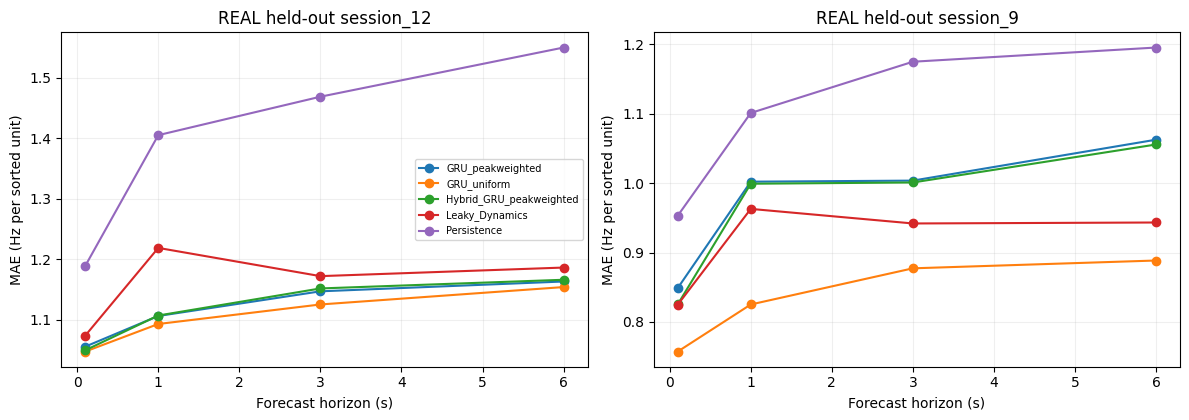

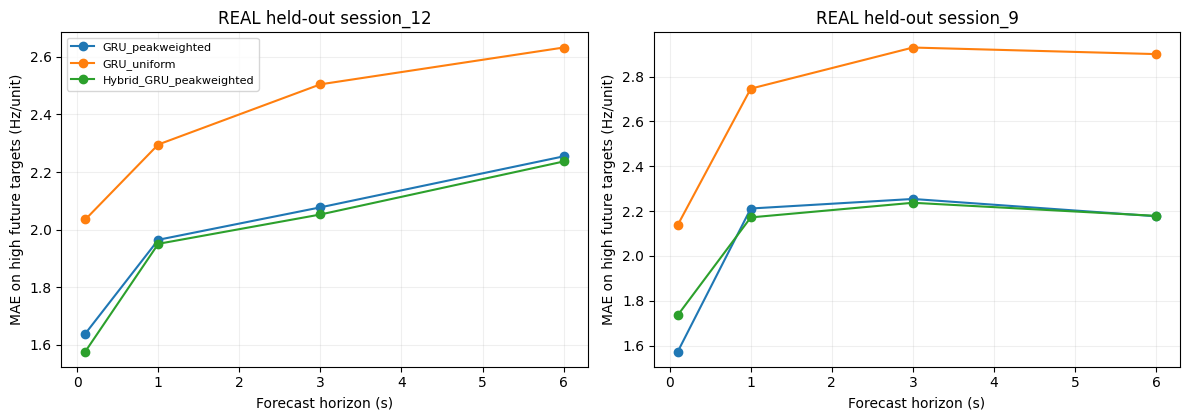

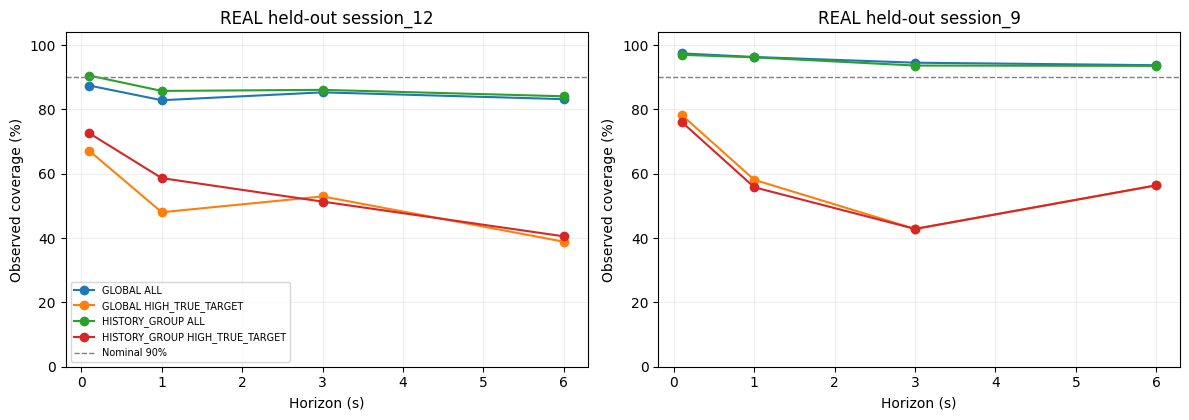

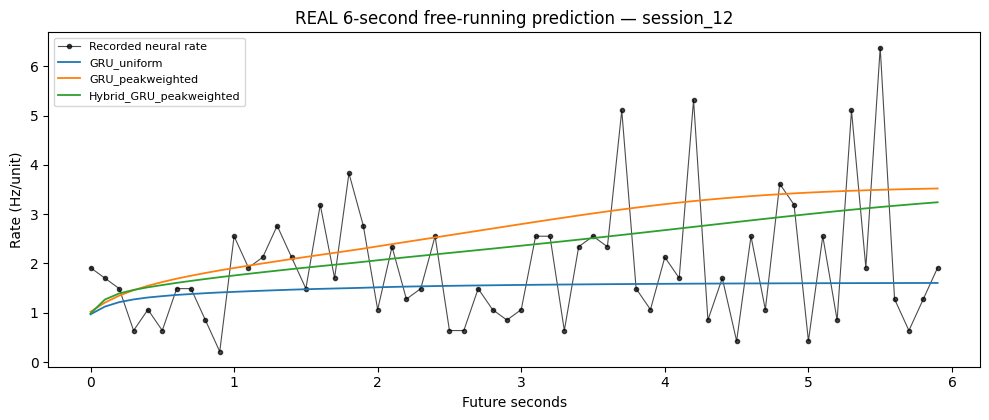

In [10]:
metric_df=pd.DataFrame(METRICS);int_df=pd.DataFrame(INTERVAL_METRICS)
fig,axs=plt.subplots(1,2,figsize=(12,4.3))
for ax,(ses,d) in zip(axs,metric_df.query('group=="ALL"').groupby('heldout_session')):
    for kind,g in d.groupby('model'):
        g=g.set_index('horizon').reindex(HORIZON_NAMES)
        ax.plot(HORIZONS*BIN_SEC,g.MAE_Hz.to_numpy(),'o-',label=kind)
    ax.set_xlabel('Forecast horizon (s)');ax.set_ylabel('MAE (Hz per sorted unit)')
    ax.set_title('REAL held-out '+ses);ax.grid(alpha=.2)
axs[0].legend(fontsize=7);fig.tight_layout()
fig.savefig(OUT/'fig1_REAL_all_activity_MAE.png',dpi=170);plt.show()

fig,axs=plt.subplots(1,2,figsize=(12,4.3))
for ax,(ses,d) in zip(axs,metric_df.query('group=="HIGH_TRUE_TARGET"').groupby('heldout_session')):
    for kind,g in d.groupby('model'):
        if kind not in KINDS:continue
        g=g.set_index('horizon').reindex(HORIZON_NAMES)
        ax.plot(HORIZONS*BIN_SEC,g.MAE_Hz.to_numpy(),'o-',label=kind)
    ax.set_xlabel('Forecast horizon (s)');ax.set_ylabel('MAE on high future targets (Hz/unit)')
    ax.set_title('REAL held-out '+ses);ax.grid(alpha=.2)
axs[0].legend(fontsize=8);fig.tight_layout()
fig.savefig(OUT/'fig2_REAL_high_target_MAE.png',dpi=170);plt.show()

fig,axs=plt.subplots(1,2,figsize=(12,4.3))
plot=int_df[(int_df.model=='GRU_peakweighted') &
            (int_df.group.isin(['ALL','HIGH_TRUE_TARGET_REVIEW_ONLY']))]
for ax,(ses,d) in zip(axs,plot.groupby('heldout_session')):
    for (method,group),g in d.groupby(['method','group']):
        g=g.set_index('horizon').reindex(HORIZON_NAMES)
        ax.plot(HORIZONS*BIN_SEC,100*g.coverage.to_numpy(),'o-',
                label=method.replace('_ABSOLUTE','')+' '+group.replace('_REVIEW_ONLY',''))
    ax.axhline(90,ls='--',lw=1,color='gray',label='Nominal 90%')
    ax.set_ylim(0,104);ax.set_xlabel('Horizon (s)');ax.set_ylabel('Observed coverage (%)')
    ax.set_title('REAL held-out '+ses);ax.grid(alpha=.2)
axs[0].legend(fontsize=7);fig.tight_layout()
fig.savefig(OUT/'fig3_REAL_uncertainty_coverage_vs_peaks.png',dpi=170);plt.show()

if FIRST_PLOT is not None:
    ses,real,preds=FIRST_PLOT
    fig,ax=plt.subplots(figsize=(10,4.3));time=np.arange(len(real))*BIN_SEC
    ax.plot(time,real,'.-',color='black',lw=.8,alpha=.7,label='Recorded neural rate')
    for kind in KINDS:ax.plot(time,preds[kind],lw=1.3,label=kind)
    ax.set_xlabel('Future seconds');ax.set_ylabel('Rate (Hz/unit)')
    ax.set_title('REAL 6-second free-running prediction — '+ses);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(OUT/'fig4_REAL_recursive_forecast.png',dpi=170);plt.show()

## 11. OPTIONAL Phase 4A preview: simulation-only constrained receding-horizon MPC

**THIS SECTION IS NOT VALIDATION OF OPTICAL STIMULATION.** The observed DANDI sequences trained a neural-rate predictor in light-free periods. Here we *invent* an inhibitory optical gain, a decay time, noise, and a control objective. The controller plans using a different simplified leaky forecast than the learned GRU-based simulated plant, and model gain mismatch is explicitly varied.

Compare no stimulation, fixed periodic stimulation, a threshold controller, and toy MPC under **identical simulated disturbances**. All actions are arbitrary dimensionless units from 0 to 1; **no dose, efficacy, or clinical safety claims**. Any beneficial outcomes reflect the chosen simulation assumptions.

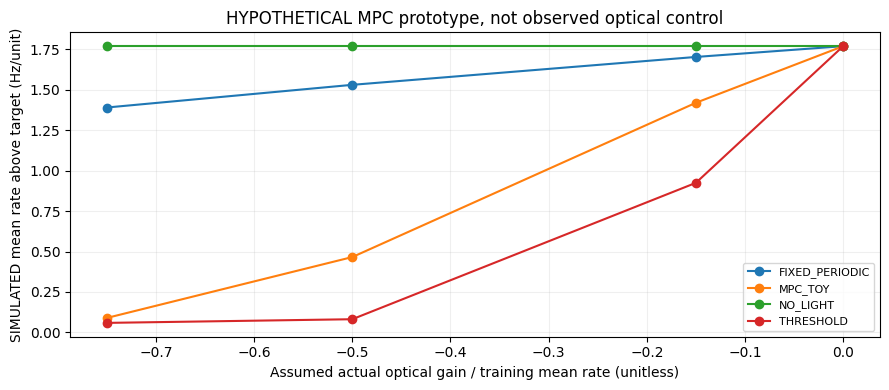

SIMULATION ONLY — no measured stimulation effect:
 assumed_actual_gain_Hz_per_unit         policy  sim_mean_rate_Hz  sim_mean_rate_above_target_Hz  sim_frac_above_target  dimensionless_total_action  fraction_action_nonzero  all_rates_finite_nonnegative
                           0.000       NO_LIGHT             3.244                          1.768                  1.000                        0.00                    0.000                          True
                           0.000 FIXED_PERIODIC             3.244                          1.768                  1.000                        5.00                    0.143                          True
                           0.000      THRESHOLD             3.244                          1.768                  1.000                       52.50                    1.000                          True
                           0.000        MPC_TOY             3.244                          1.768                  1.000                   

In [11]:
# Toy controller: nominal model uses leaky dynamics; SIMULATED plant uses real-data-trained GRU
# + assumed optical suppression. This is a method demonstration, NOT a measured result.
rec=RUNS[1]
INITIAL=rec['splits']['test']['X'][0]
mu=max(.1,float(rec['params']['mu_Hz']))
target=.80*mu
u_set=[0.,.25,.5,.75,1.]
rho=float(np.exp(-BIN_SEC/.25))
assumed_beta=-.50*mu  # HYPOTHETICAL (Hz per unit optical activation)
N_STEPS=N_MPC_STEPS
rng=np.random.default_rng(SEED)
shared_disturbance=rng.normal(0,.12*mu,N_STEPS)
shared_disturbance[25:32]+=.30*mu  # artificial, not observed neural event

def controller_choice(policy,history,z,last_action,step):
    cur=float(history[-1])
    if policy=='NO_LIGHT':return 0.
    if policy=='FIXED_PERIODIC':return .5 if step%7==0 else 0.
    if policy=='THRESHOLD':return .75 if cur>target else 0.
    assert policy=='MPC_TOY'
    # Three-step receding-horizon plan with constant candidate action;
    # MPC planning surrogate is LEAKY and differs from the GRU plant.
    vals=[]
    for u in u_set:
        zz=z;future=cur;cost=0.
        for k in range(1,4):
            zz=rho*zz+(1-rho)*u
            future=rec['params']['mu_Hz']+rec['params']['alpha']*(future-rec['params']['mu_Hz'])
            pred_rate=max(0.,future+assumed_beta*zz)
            cost+=max(0,pred_rate-target)**2 + (.05*mu**2)*(u**2)
        cost+=(.04*mu**2)*(u-last_action)**2
        vals.append(cost)
    return float(u_set[int(np.argmin(vals))])

SIMULATED_RESULTS=[];SIMULATED_TRACE=[]
for gain in [0.,-.15*mu,-.50*mu,-.75*mu]:
    for policy in ['NO_LIGHT','FIXED_PERIODIC','THRESHOLD','MPC_TOY']:
        history=list(INITIAL.astype(float));z=0.;last=0.;actions=[];rates=[]
        for t in range(N_STEPS):
            u=controller_choice(policy,history,z,last,t)
            z=rho*z+(1-rho)*u
            # The neural baseline is a learned GRU but its optical response was NEVER fitted.
            base=predict_one_history(history[-HISTORY_BINS:],'GRU_peakweighted',rec)
            rate=float(np.clip(base+gain*z+shared_disturbance[t],0,500))
            history.append(rate);actions.append(u);rates.append(rate);last=u
            SIMULATED_TRACE.append({'sim_gain_Hz_per_unit':gain,'policy':policy,
                'step':t,'t_sec':t*BIN_SEC,'sim_rate_Hz':rate,'assumed_action':u,'sim_z':z})
        rates=np.asarray(rates);actions=np.asarray(actions)
        SIMULATED_RESULTS.append({'assumed_actual_gain_Hz_per_unit':gain,'policy':policy,
            'sim_mean_rate_Hz':float(np.mean(rates)),
            'sim_mean_rate_above_target_Hz':float(np.mean(np.maximum(0,rates-target))),
            'sim_frac_above_target':float(np.mean(rates>target)),
            'dimensionless_total_action':float(actions.sum()),
            'fraction_action_nonzero':float(np.mean(actions>0)),
            'all_rates_finite_nonnegative':bool(np.isfinite(rates).all() and (rates>=0).all())})
assert all(x['all_rates_finite_nonnegative'] for x in SIMULATED_RESULTS)
pd.DataFrame(SIMULATED_RESULTS).to_csv(OUT/'SIMULATED_MPC_toy_policy_comparison_NOT_OBSERVED.csv',index=False)
pd.DataFrame(SIMULATED_TRACE).to_csv(OUT/'SIMULATED_MPC_toy_trajectories_NOT_OBSERVED.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
for p,d in pd.DataFrame(SIMULATED_RESULTS).groupby('policy'):
    ax.plot(d.assumed_actual_gain_Hz_per_unit/mu,d.sim_mean_rate_above_target_Hz,'o-',label=p)
ax.set_xlabel('Assumed actual optical gain / training mean rate (unitless)')
ax.set_ylabel('SIMULATED mean rate above target (Hz/unit)')
ax.set_title('HYPOTHETICAL MPC prototype, not observed optical control')
ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(OUT/'fig5_SIMULATED_MPC_toy_gain_sensitivity_NOT_OBSERVED.png',dpi=170);plt.show()
print('SIMULATION ONLY — no measured stimulation effect:')
print(pd.DataFrame(SIMULATED_RESULTS).round(3).to_string(index=False))

## 12. Verify all outputs, record limitations, and export ZIP

This notebook **must never** replace failed real-data calculations with simulated results. Reports include both observed and simulation outputs with unambiguous filenames. Review full-mode and new biological datasets before claiming generalizability.

In [12]:
prov={'phase':'3C','dandiset':DANDISET,'version':VERSION,'dataset_sessions':list(session_files),
      'species':'mouse','independent_animals':1,
      'targets':'light-free population firing rate in Hz/sorted-unit',
      'biological_model':'nonnegative leaky rate baseline + GRU residual (not circuit identified)',
      'models':KINDS,'peak_loss_multiplier':PEAK_WEIGHT,
      'train_high_activity_threshold':'90th percentile per prediction horizon, training split only',
      'history_gate':'past 0.5 second max; high if above train 80th percentile',
      'interval_methods':['GLOBAL_ABSOLUTE','HISTORY_GROUP_ABSOLUTE'],
      'interval_alpha':ALPHA,
      'calibration':'chronological training-session calibration period; no test labels used',
      'guarantee_warning':'Temporal dependence and held-out-session shift invalidate distribution-free coverage guarantees',
      'simulation_warning':'All optical gains and MPC effects are assumed, not observed or biologically validated',
      'cross_animal':'NOT TESTED: both sessions same mouse',
      'clinical':'No epilepsy diagnosis, seizure suppression, patient personalization, or treatment efficacy',
      'generated_utc':datetime.now(timezone.utc).isoformat(),
      'quick_mode':QUICK_MODE,'epochs':EPOCHS,'ensemble_size_per_kind':N_ENSEMBLE}
(OUT/'STUDY_PROVENANCE_AND_LIMITATIONS.json').write_text(json.dumps(prov,indent=2))
(OUT/'README_RESULTS.txt').write_text(
    'REAL_* and fig1_REAL to fig4_REAL: measured spontaneous neural-rate predictions.\n'
    'SIMULATED_* and fig5_SIMULATED: completely hypothetical stimulation controller.\n'
    'Results cover two sessions from one mouse; NOT cross-animal, human, epilepsy or therapy.\n'
    'Nominal 90% interval coverage should not be presented as a formal guarantee under session shift.\n')
required=['REAL_prediction_metrics_by_group.csv','REAL_heldout_predictions.csv',
          'REAL_interval_coverage_and_width_by_group.csv','REAL_calibrated_interval_predictions.csv',
          'REAL_free_running_multistep_metrics.csv',
          'SIMULATED_MPC_toy_policy_comparison_NOT_OBSERVED.csv',
          'STUDY_PROVENANCE_AND_LIMITATIONS.json']
for filename in required:
    f=OUT/filename
    assert f.exists() and f.stat().st_size>20,filename
for filename in ['REAL_heldout_predictions.csv','REAL_calibrated_interval_predictions.csv']:
    tab=pd.read_csv(OUT/filename)
    assert len(tab)>100 and not tab.isnull().all(axis=1).any(),filename
archive=ROOT/'phase3c_peak_aware_twin_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in sorted(OUT.iterdir()):
        if f.is_file():z.write(f,arcname=f.name)
print('COMPLETE:',archive,'MB:',round(archive.stat().st_size/1e6,2))
print('Upload the ZIP for scientific audit. Do not report simulation as optogenetic response evidence.')

COMPLETE: /kaggle/working/phase3c_peak_aware_twin_results.zip MB: 2.61
Upload the ZIP for scientific audit. Do not report simulation as optogenetic response evidence.


## 13. How to interpret this phase

**Evidence gate:** (1) Does peak-weighted GRU improve high-target MAE in **both** held-out-session directions? (2) Does it preserve acceptable overall MAE? (3) Do the interval methods achieve reasonable **empirical** nominal coverage, especially during future high activity? (4) Do recursive 6-second rollouts improve? (5) Do confidence findings remain honest under the domain shift?

**Next:** If benefits repeat, freeze the robust neural-rate predictor and progress to more extensive simulated-control tests. If not, do not add unnecessary complexity: use the better ordinary GRU. **The MPC section above is an educational in-silico prototype. Optical-action effects were not learned from experimental stimulation labels.**